# Determinants of Life Expectancy and Child Mortality### A Cross-Country Analysis Using World Bank Data**Data source:** World Bank, *World Development Indicators* ([DataBank](https://databank.worldbank.org/source/world-development-indicators))## Project overviewThis project analyzes health and development indicators across countries from 2000 to 2023. It explores patterns in life expectancy and child mortality in relation to healthcare spending, immunization, water access, income, urbanization and fertility.Statistical analysis and machine learning are used to explore relationships, identify important factors and evaluate prediction models.

**Analysis period:** 2000–2023. The downloaded source file also contains 2024; it is excluded because several indicators have substantial missing data.


# Part 0. Setup and data loading

In [1]:
import os, io, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")

OUT = "outputs"
FIG = os.path.join(OUT, "figures")
TABLES = os.path.join(OUT, "tables")
os.makedirs(FIG, exist_ok=True)
os.makedirs(TABLES, exist_ok=True)

In [2]:
DATA_FILE = os.path.join("data", "raw", "DA PROJ DATA.csv")
if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}. Keep the data folder beside this notebook.")
raw_bytes = open(DATA_FILE, "rb").read()
print("Using project dataset:", DATA_FILE)

Using project dataset: data/raw/DA PROJ DATA.csv


In [ ]:
for enc in ["utf-8-sig", "latin-1"]:
    try:
        raw = pd.read_csv(io.BytesIO(raw_bytes), encoding=enc)
        print("Loaded with encoding:", enc)
        break
    except Exception:
        print(enc, "failed")
print("Shape:", raw.shape)

# Part 1. Data understanding

In [ ]:
print("Rows, columns:", raw.shape)
print("\nColumn types:\n", raw.dtypes.value_counts())
print("\nFirst rows (first 6 columns):")
display(raw.iloc[:3, :6])
print("Last rows (footer):")
display(raw.tail(6).iloc[:, :4])
print("Full-row duplicates:", raw.duplicated().sum())
print("Distinct entities (countries + aggregates):", raw["Country Code"].nunique())
print("\n'..' placeholders per column (top 8):")
print((raw == "..").sum().sort_values(ascending=False).head(8))

# Part 2. Data cleaning

### 2.1 Remove footer rows, rename columns and convert data types

In [ ]:
df = raw.dropna(subset=["Country Code"]).copy()
print("After removing footer rows:", df.shape)            # expect (6650, 25)

code_map = {
 "SP.DYN.LE00.IN":"life_exp", "SH.DYN.MORT":"u5_mort", "SH.DYN.MORT.FE":"u5_mort_f",
 "SH.DYN.MORT.MA":"u5_mort_m", "SH.XPD.CHEX.GD.ZS":"health_gdp", "SH.XPD.CHEX.PC.CD":"health_pc",
 "SH.IMM.IDPT":"dpt", "SH.IMM.MEAS":"measles", "SH.MED.PHYS.ZS":"physicians",
 "SH.H2O.BASW.ZS":"water", "SH.STA.SMSS.ZS":"sanitation", "NY.GDP.PCAP.CD":"gdp_pc",
 "SE.ADT.LITR.ZS":"literacy", "SP.URB.TOTL.IN.ZS":"urban_pct", "SP.DYN.TFRT.IN":"fertility",
 "SI.POV.DDAY":"poverty", "SP.POP.TOTL.FE.IN":"pop_f", "SP.POP.TOTL.FE.ZS":"pop_f_pct",
 "SP.POP.TOTL.MA.IN":"pop_m", "SP.POP.TOTL.MA.ZS":"pop_m_pct", "SP.POP.TOTL":"population"}

def new_name(c):
    if "[" in c:
        return code_map.get(c.split("[")[-1].rstrip("]"), c)
    return {"Time":"year", "Country Name":"country", "Country Code":"code"}.get(c, c)

df.columns = [new_name(c) for c in df.columns]
df = df.drop(columns=["Time Code"])

num_cols = list(code_map.values())
df[num_cols] = df[num_cols].replace("..", np.nan).apply(pd.to_numeric, errors="coerce")
df["year"] = df["year"].astype(int)

print("Column types now:\n", df.dtypes.value_counts())
print("Full-row duplicates:", df.duplicated().sum())
print("Duplicate (country, year) pairs:", df.duplicated(["code", "year"]).sum())

### 2.2 Standardise categories and remove aggregates

In [6]:
META_FILE = os.path.join("data", "processed", "country_metadata.csv")
if not os.path.exists(META_FILE):
    raise FileNotFoundError(f"Country metadata not found: {META_FILE}")
econ = pd.read_csv(META_FILE)
df = df.merge(econ[["code", "aggregate", "region", "income_group"]], on="code", how="left")

df = df[(df["aggregate"] == False) & df["region"].notna()].copy()
df = df.drop(columns="aggregate")

for c in ["country", "region", "income_group"]:
    df[c] = df[c].str.strip()

print("Countries:", df["code"].nunique(), "| Rows:", df.shape[0])
print("Regions:", sorted(df["region"].dropna().unique()))
print("Income groups:", sorted(df["income_group"].dropna().unique()))

Countries: 190 | Rows: 4750
Regions: ['East Asia & Pacific', 'Europe & Central Asia', 'Latin America & Caribbean', 'Middle East, N. Africa, Afghanistan & Pakistan', 'North America', 'South Asia', 'Sub-Saharan Africa']
Income groups: ['High income', 'Low income', 'Lower middle income', 'Upper middle income']


### 2.3 Validate the time variable

In [ ]:
print("Years:", df["year"].min(), "to", df["year"].max())
print("Years per country (count of countries):", df.groupby("code")["year"].nunique().value_counts().to_dict())
assert df["year"].between(2000, 2024).all(), "unexpected year found"

### 2.4 Missing-value analysis

In [ ]:
null_report = pd.DataFrame({"missing": df[num_cols].isna().sum(),
                            "missing_%": (df[num_cols].isna().mean() * 100).round(1)}
                          ).sort_values("missing_%", ascending=False)
print(null_report)

In [ ]:
cols = ["life_exp","u5_mort","health_gdp","health_pc","dpt","measles","sanitation",
        "water","physicians","gdp_pc","literacy","poverty"]
by_year = df.groupby("year")[cols].apply(lambda g: g.isna().mean()).round(2)
print(by_year)

plt.figure(figsize=(12, 9))
sns.heatmap(by_year, annot=True, cmap="Reds", vmin=0, vmax=1)
plt.title("Share of missing values by year and indicator")
plt.savefig(FIG + "/missing_by_year.png", dpi=300, bbox_inches="tight")
plt.show()

### 2.5 Select the analysis period and variables

      life_exp  u5_mort  health_gdp  health_pc   dpt  measles  sanitation  \
year                                                                        
2000       0.0      0.1        0.15       0.15  0.12     0.12        0.37   
2001       0.0      0.1        0.15       0.15  0.12     0.12        0.36   
2002       0.0      0.1        0.15       0.15  0.12     0.12        0.35   
2003       0.0      0.1        0.14       0.14  0.12     0.12        0.35   
2004       0.0      0.1        0.14       0.14  0.12     0.12        0.35   
2005       0.0      0.1        0.14       0.14  0.12     0.12        0.35   
2006       0.0      0.1        0.14       0.14  0.12     0.12        0.34   
2007       0.0      0.1        0.14       0.14  0.12     0.12        0.34   
2008       0.0      0.1        0.14       0.14  0.12     0.12        0.34   
2009       0.0      0.1        0.14       0.14  0.12     0.12        0.34   
2010       0.0      0.1        0.13       0.13  0.12     0.12        0.34   

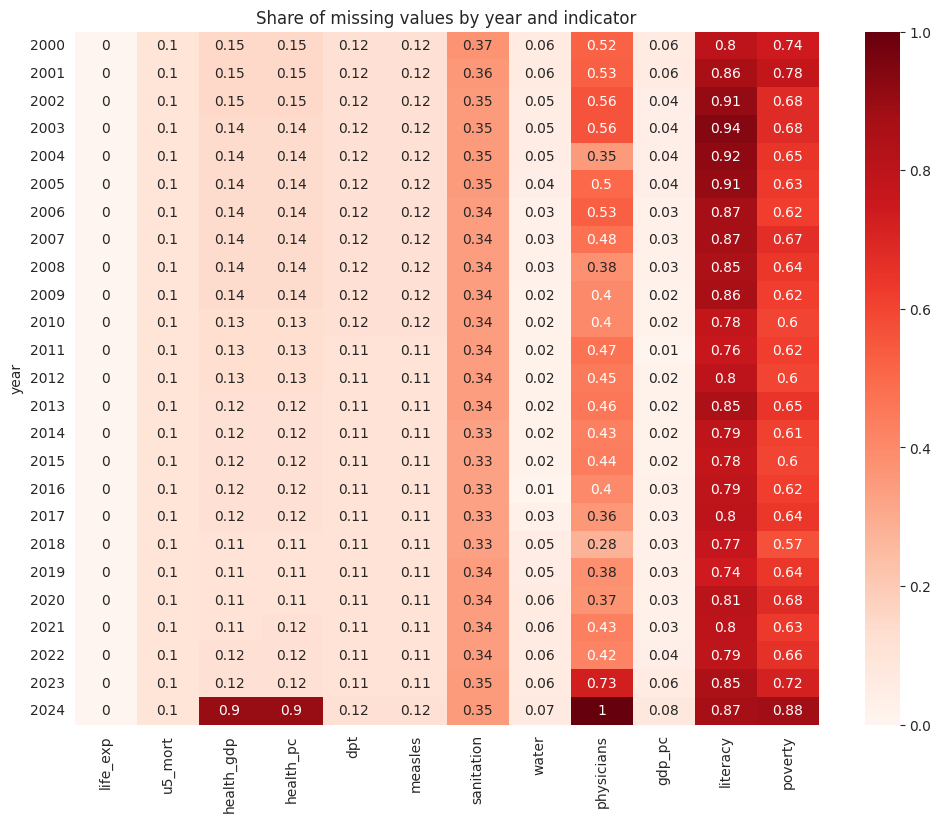

In [9]:
df = df[df["year"] <= 2023].copy()
df = df.drop(columns=["u5_mort_f", "u5_mort_m", "pop_f", "pop_m", "pop_f_pct", "pop_m_pct"])
print("After trimming years and dropping by-sex columns:", df.shape)

has_outcome = df.groupby("country")[["life_exp", "u5_mort"]].apply(
    lambda g: g.notna().any().all())
no_outcome = has_outcome[~has_outcome].index.tolist()
print("\nDropped (no outcome data):", no_outcome)
df = df[~df["country"].isin(no_outcome)].copy()
print("Countries:", df["country"].nunique(), "| Rows:", df.shape[0])      # expect 196 and 4704

### 2.6 Impute missing values

In [ ]:
df = df.sort_values(["country", "year"])
fill_cols = ["health_gdp", "health_pc", "dpt", "measles", "water", "sanitation", "gdp_pc"]

def fill(s):
    s = s.interpolate(method="linear", limit_area="inside")   # gaps between known years
    return s.ffill(limit=2).bfill(limit=2)                    # at most 2 years at the ends

before = df[fill_cols].isna().sum()
df[fill_cols] = df.groupby("country")[fill_cols].transform(fill)
print(pd.DataFrame({"missing_before": before, "missing_after": df[fill_cols].isna().sum()}))
print("\nMissing categorical labels:", df[["region", "income_group"]].isna().sum().to_dict())

# Main dataset: countries with all core variables present
core = ["health_gdp", "health_pc", "dpt", "measles", "water", "gdp_pc", "urban_pct", "fertility"]
main = df.dropna(subset=core).copy()
print("\nMAIN:", main.shape, "|", main["country"].nunique(), "countries")   # expect 4465 and 191

**Result:** Imputation reduces missingness only slightly because many remaining gaps cover entire countries rather than isolated years.

### 2.7 Validate ranges and duplicates

In [ ]:
pct = ["dpt", "measles", "water", "sanitation", "urban_pct", "literacy", "poverty", "health_gdp"]
for c in pct:
    print(c, "out of 0-100 range:", ((main[c] < 0) | (main[c] > 100)).sum())
print("Duplicate country-years:", main.duplicated(["country", "year"]).sum())

print("\nLife expectancy outside 20-90 years:", ((main["life_exp"] < 20) | (main["life_exp"] > 90)).sum())
print("Under-5 mortality above 400 per 1,000:", (main["u5_mort"] > 400).sum())
print(main.loc[(main["life_exp"] < 20) | (main["u5_mort"] > 400), ["country", "year", "life_exp", "u5_mort"]])

### 2.8 Detect outliers using the IQR rule

In [ ]:
check = ["life_exp", "u5_mort", "health_gdp", "health_pc", "dpt", "measles",
         "water", "gdp_pc", "urban_pct", "fertility", "population"]
outliers = {}
for c in check:
    q1, q3 = main[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers[c] = ((main[c] < q1 - 1.5 * iqr) | (main[c] > q3 + 1.5 * iqr)).sum()
print("IQR outliers per variable:\n", pd.Series(outliers).sort_values(ascending=False))
print("\nSkewness:\n", main[check].skew().round(2).sort_values(ascending=False))

fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for a, c in zip(ax.flat, ["life_exp", "u5_mort", "health_gdp", "health_pc",
                          "gdp_pc", "population", "dpt", "fertility"]):
    sns.boxplot(y=main[c], ax=a, color="lightsteelblue"); a.set_title(c)
plt.tight_layout()
plt.savefig(FIG + "/boxplots_outliers.png", dpi=300)
plt.show()

### 2.9 Investigate suspicious values: Central African Republic

In [ ]:
car = main[main["country"] == "Central African Republic"][["year", "life_exp", "u5_mort"]]
print(car.to_string(index=False))

le_median = main.groupby("country")["life_exp"].transform(
    lambda s: s.rolling(5, center=True, min_periods=3).median())
flag = main[(main["life_exp"] - le_median).abs() > 8]
print("\nRolling-median screen:")
print(flag[["country", "year", "life_exp"]].assign(median=le_median[flag.index]).round(1).to_string(index=False))

**Decision:** The Central African Republic is excluded because its reported life-expectancy values include implausible drops that are inconsistent with adjacent years. Other unusual observations are retained when they reflect plausible crisis conditions.

In [ ]:
D = main[main["country"] != "Central African Republic"].copy()
print("Final analysis dataset D:", D.shape, "|", D["country"].nunique(), "countries")   # expect (4441, 20) and 190

# Part 3. Feature engineering and data dictionary### 3.1 Create derived features

In [ ]:
D = D.sort_values(["country", "year"]).copy()
D["log_health_pc"] = np.log1p(D["health_pc"])
D["log_gdp_pc"] = np.log1p(D["gdp_pc"])
D["log_population"] = np.log1p(D["population"])
D["log_u5_mort"] = np.log1p(D["u5_mort"])
D["avg_immunization"] = D[["dpt", "measles"]].mean(axis=1)
D["life_exp_change"] = D.groupby("country")["life_exp"].diff()      # EDA only
D["covid_period"] = (D["year"] >= 2020).astype(int)
D["mort_risk"] = (D["u5_mort"] > 25).astype(int)                    # 1 = high risk (SDG 3.2)

print("Risk class balance:\n", D["mort_risk"].value_counts(normalize=True).round(2))
print("Shape:", D.shape)

### 3.2 Data dictionary

In [ ]:
data_dict = pd.DataFrame([
 ["country",          "Country name",                                              "text",                  "World Bank country list"],
 ["code",             "ISO 3-letter country code",                                 "text",                  "World Bank country list"],
 ["year",             "Calendar year",                                             "year",                  "-"],
 ["region",           "World Bank region",                                         "category",              "Bundled country_metadata.csv"],
 ["income_group",     "World Bank income classification",                          "category",              "Bundled country_metadata.csv"],
 ["life_exp",         "Life expectancy at birth, total",                           "years",                 "SP.DYN.LE00.IN"],
 ["u5_mort",          "Under-5 mortality rate",                                    "deaths per 1,000 births","SH.DYN.MORT"],
 ["health_gdp",       "Current health expenditure",                                "% of GDP",              "SH.XPD.CHEX.GD.ZS"],
 ["health_pc",        "Current health expenditure per person",                     "current US$",           "SH.XPD.CHEX.PC.CD"],
 ["dpt",              "DPT immunization, children aged 12-23 months",              "%",                     "SH.IMM.IDPT"],
 ["measles",          "Measles immunization, children aged 12-23 months",          "%",                     "SH.IMM.MEAS"],
 ["water",            "People using at least basic drinking-water services",       "% of population",       "SH.H2O.BASW.ZS"],
 ["sanitation",       "People using safely managed sanitation services",           "% of population",       "SH.STA.SMSS.ZS"],
 ["physicians",       "Physicians",                                                "per 1,000 people",      "SH.MED.PHYS.ZS"],
 ["literacy",         "Adult literacy rate, ages 15 and above",                    "%",                     "SE.ADT.LITR.ZS"],
 ["poverty",          "Poverty headcount ratio at $3.00 a day (2021 PPP)",         "% of population",       "SI.POV.DDAY"],
 ["gdp_pc",           "GDP per person",                                            "current US$",           "NY.GDP.PCAP.CD"],
 ["urban_pct",        "Urban population",                                          "% of total population", "SP.URB.TOTL.IN.ZS"],
 ["fertility",        "Total fertility rate",                                      "births per woman",      "SP.DYN.TFRT.IN"],
 ["population",       "Total population",                                          "people",                "SP.POP.TOTL"],
 ["log_health_pc",    "log(1 + health_pc)",                                        "engineered",            "derived"],
 ["log_gdp_pc",       "log(1 + gdp_pc)",                                           "engineered",            "derived"],
 ["log_population",   "log(1 + population)",                                       "engineered",            "derived"],
 ["log_u5_mort",      "log(1 + u5_mort)",                                          "engineered",            "derived"],
 ["avg_immunization", "Mean of dpt and measles",                                   "engineered, %",         "derived"],
 ["life_exp_change",  "Yearly change in life expectancy (EDA only)",               "engineered, years",     "derived"],
 ["covid_period",     "1 if year >= 2020, else 0",                                 "engineered, 0/1",       "derived"],
 ["mort_risk",        "1 if under-5 mortality > 25 per 1,000 (SDG 3.2 target)",    "engineered, 0/1",       "derived"],
], columns=["column", "meaning", "unit", "source / WDI series code"])
display(data_dict)

### 3.3 Select model features and targets

In [ ]:
id_cols  = ["country", "code", "year"]
cat_cols = ["region", "income_group"]
targets  = ["life_exp", "mort_risk"]

features = ["log_health_pc", "health_gdp", "avg_immunization", "water",
            "log_gdp_pc", "urban_pct", "fertility"]

excluded = {
    "country, code":                      "identifiers, not predictors",
    "year":                               "would let the model memorise time, not explain health",
    "u5_mort, log_u5_mort":               "define the risk label and are 94% correlated with life expectancy (leakage)",
    "life_exp_change":                    "derived from the target",
    "health_pc, gdp_pc, population":      "raw versions replaced by log versions",
    "dpt, measles":                       "replaced by avg_immunization",
    "sanitation, physicians, literacy, poverty": "too sparse; tested separately in Part 8",
}
print("MODEL FEATURES:", features)
print("\nEXCLUDED:")
for k, v in excluded.items():
    print(f"  {k:45s} -> {v}")

# Part 4. Exploratory data analysis

### 4.1 Summary statistics and distributions

In [ ]:
core_vars = ["life_exp", "u5_mort", "health_gdp", "health_pc", "dpt", "measles",
             "water", "gdp_pc", "urban_pct", "fertility", "population"]
summary_stats = D[core_vars].describe().T.round(2)
print(summary_stats)

fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for i, (r, l) in enumerate([("health_pc", "log_health_pc"), ("gdp_pc", "log_gdp_pc"),
                            ("population", "log_population"), ("u5_mort", "log_u5_mort")]):
    sns.histplot(D[r], bins=40, ax=ax[0, i], color="steelblue"); ax[0, i].set_title(r + " (raw)")
    sns.histplot(D[l], bins=40, ax=ax[1, i], color="seagreen");  ax[1, i].set_title(l + " (log)")
plt.tight_layout()
plt.savefig(FIG + "/skew_before_after.png", dpi=300)
plt.show()

fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for a, c in zip(ax.flat, ["life_exp", "health_gdp", "dpt", "measles", "water", "urban_pct", "fertility"]):
    sns.histplot(D[c], bins=40, kde=True, color="steelblue", ax=a); a.set_title(c)
ax.flat[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG + "/distributions.png", dpi=300)
plt.show()

### 4.2 Trends over time and regional differences

In [ ]:
order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for v, a, t in zip(["life_exp", "u5_mort", "avg_immunization"], ax,
                   ["Life expectancy (years)", "Under-5 mortality (per 1,000)", "Average immunization (%)"]):
    sns.lineplot(data=D, x="year", y=v, hue="income_group", hue_order=order,
                 errorbar=None, ax=a)
    a.set_title(t)
    a.axvspan(2020, 2021, color="grey", alpha=0.15)      # COVID years
plt.tight_layout()
plt.savefig(FIG + "/trends_income.png", dpi=300)
plt.show()

print(D.groupby("region")[["life_exp", "u5_mort"]].mean().round(1))
print("\nMean life expectancy, last 6 years:")
print(D.groupby("year")["life_exp"].mean().round(2).tail(6))

### 4.3 Relationships and correlation

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
for a, x in zip(ax.flat, ["log_health_pc", "health_gdp", "avg_immunization",
                          "water", "log_gdp_pc", "urban_pct"]):
    sns.scatterplot(data=D, x=x, y="life_exp", hue="income_group", hue_order=order,
                    alpha=0.4, s=15, ax=a, legend=(x == "log_health_pc"))
    sns.regplot(data=D, x=x, y="life_exp", scatter=False, color="black", ax=a)
    a.set_title("Life expectancy vs " + x)
plt.tight_layout()
plt.savefig(FIG + "/scatter.png", dpi=300)
plt.show()

cc = ["life_exp", "log_u5_mort", "log_health_pc", "health_gdp", "avg_immunization",
      "water", "log_gdp_pc", "urban_pct", "fertility", "log_population"]
corr = D[cc].corr(method="spearman").round(2)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation matrix")
plt.savefig(FIG + "/corr_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values()
print("Strongest negative:\n", pairs.head(3))
print("\nStrongest positive:\n", pairs.tail(3))

### 4.4 Group comparisons and Pakistan

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for a, v in zip(ax, ["life_exp", "u5_mort", "log_health_pc"]):
    sns.boxplot(data=D, x="income_group", y=v, order=order, ax=a)
    a.tick_params(axis="x", rotation=20); a.set_title(v)
plt.tight_layout()
plt.savefig(FIG + "/box_income.png", dpi=300)
plt.show()

pk = D[D["country"] == "Pakistan"]
print(pk[["year", "life_exp", "u5_mort", "health_gdp", "health_pc", "dpt", "water"]].tail(6).round(1))

pk_inc, pk_reg = pk["income_group"].iloc[0], pk["region"].iloc[0]
compare = pd.DataFrame({
    "Pakistan": pk.set_index("year")["life_exp"],
    pk_inc: D[D["income_group"] == pk_inc].groupby("year")["life_exp"].mean(),
    pk_reg: D[D["region"] == pk_reg].groupby("year")["life_exp"].mean()})
compare.plot(figsize=(10, 6), title="Life expectancy: Pakistan vs peers")
plt.ylabel("Years")
plt.savefig(FIG + "/pakistan.png", dpi=300)
plt.show()

# Part 5. Statistical analysis

### 5.1 Normality

In [ ]:
for c in ["life_exp", "log_u5_mort", "log_health_pc", "log_gdp_pc"]:
    w, p = stats.shapiro(D[c])
    print(f"{c}: W={w:.3f}, p={p:.1e}, skew={D[c].skew():.2f}, kurtosis={D[c].kurt():.2f}")

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, c in zip(ax, ["life_exp", "log_u5_mort", "log_health_pc", "log_gdp_pc"]):
    sm.qqplot(D[c], line="s", ax=a); a.set_title("Q-Q: " + c)
plt.tight_layout()
plt.savefig(FIG + "/qq.png", dpi=300)
plt.show()

### 5.2 Correlation tests

In [ ]:
predictors = ["log_health_pc", "health_gdp", "avg_immunization", "water",
              "log_gdp_pc", "urban_pct", "fertility"]
rows = []
for target in ["life_exp", "log_u5_mort"]:
    for x in predictors:
        r, p = stats.pearsonr(D[x], D[target])
        rho, p2 = stats.spearmanr(D[x], D[target])
        rows.append([target, x, round(r, 3), f"{p:.1e}", round(rho, 3), f"{p2:.1e}"])
corr_tests = pd.DataFrame(rows, columns=["target", "predictor", "pearson_r", "p", "spearman_rho", "p_spearman"])
print(corr_tests.to_string(index=False))

### 5.3 Income-group comparisons

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

groups = [g["life_exp"].values for _, g in D.groupby("income_group")]
F, p = stats.f_oneway(*groups)
H, p_kw = stats.kruskal(*groups)
ss_between = sum(len(g) * (g.mean() - D["life_exp"].mean()) ** 2 for g in groups)
ss_total = ((D["life_exp"] - D["life_exp"].mean()) ** 2).sum()
print(f"ANOVA: F={F:.1f}, p={p:.1e}, eta^2={ss_between / ss_total:.2f}")
print(f"Kruskal-Wallis: H={H:.1f}, p={p_kw:.1e}")
print(pairwise_tukeyhsd(D["life_exp"], D["income_group"]))

median_pc = D["health_pc"].median()
high = D.loc[D["health_pc"] >= median_pc, "life_exp"]
low = D.loc[D["health_pc"] < median_pc, "life_exp"]
t, p = stats.ttest_ind(high, low, equal_var=False)
d = (high.mean() - low.mean()) / np.sqrt((high.var() + low.var()) / 2)
print(f"\nHigh vs low spending: {high.mean():.1f} vs {low.mean():.1f} years, t={t:.1f}, p={p:.1e}, Cohen d={d:.2f}")

print("\nSame comparison inside each income group:")
for grp_name, sub in D.groupby("income_group"):
    m = sub["health_pc"].median()
    h = sub.loc[sub["health_pc"] >= m, "life_exp"]
    l = sub.loc[sub["health_pc"] < m, "life_exp"]
    t, p = stats.ttest_ind(h, l, equal_var=False)
    print(f"  {grp_name}: gap = {h.mean() - l.mean():.2f} years, p={p:.1e}")

### 5.4 Multiple regression and multicollinearity

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

groups_id = pd.factorize(D["country"])[0]    # rows from one country are not independent

specs = {
    "Spec A (spending per capita)": "log_health_pc + avg_immunization + water + urban_pct + fertility",
    "Spec B (GDP + spending share)": "log_gdp_pc + health_gdp + avg_immunization + water + urban_pct + fertility",
}
for spec_name, formula in specs.items():
    for target in ["life_exp", "log_u5_mort"]:
        model = smf.ols(target + " ~ " + formula, data=D).fit(
            cov_type="cluster", cov_kwds={"groups": groups_id})
        print(f"\n=== {spec_name} | {target} | R2 = {model.rsquared:.3f}")
        print(model.summary().tables[1])

    cols_x = [c.strip() for c in formula.split("+")]
    X_const = sm.add_constant(D[cols_x])
    vif = [variance_inflation_factor(X_const.values, i + 1) for i in range(len(cols_x))]
    print("VIF:", {k: round(float(v), 2) for k, v in zip(cols_x, vif)})

mA = smf.ols("life_exp ~ " + specs["Spec A (spending per capita)"], data=D).fit()
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(mA.fittedvalues, mA.resid, s=8, alpha=0.4); ax[0].axhline(0, color="red")
ax[0].set_title("Residuals vs fitted")
sm.qqplot(mA.resid, line="s", ax=ax[1]); ax[1].set_title("Residual Q-Q")
sns.histplot(mA.resid, bins=40, ax=ax[2], color="steelblue"); ax[2].set_title("Residual distribution")
plt.tight_layout()
plt.savefig(FIG + "/residuals.png", dpi=300)
plt.show()

### 5.5 Standardised coefficients

In [ ]:
vars5 = ["log_health_pc", "avg_immunization", "water", "urban_pct", "fertility"]
z = (D[vars5] - D[vars5].mean()) / D[vars5].std()
y_z = (D["life_exp"] - D["life_exp"].mean()) / D["life_exp"].std()
zm = sm.OLS(y_z, sm.add_constant(z)).fit()
std_coefs = zm.params.drop("const").sort_values(key=abs, ascending=False).round(3)
print(std_coefs)

# Part 6. Encoding, feature selection, splitting, scaling and PCA

### 6.1 Encode categorical variables

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Demonstration only (NOT used): what LabelEncoder would do to region
le = LabelEncoder()
le.fit(D["region"])
print("LabelEncoder codes (not used):", dict(zip(le.classes_, range(len(le.classes_)))))

D2 = D.copy()
D2["income_code"] = D2["income_group"].map({"Low income": 0, "Lower middle income": 1,
                                            "Upper middle income": 2, "High income": 3})
D2 = pd.get_dummies(D2, columns=["region"], drop_first=True, dtype=int)
region_cols = [c for c in D2.columns if c.startswith("region_")]
print("\nOne-hot region columns:", region_cols)

### 6.2 Define features and targets

In [ ]:
X = D2[features]
y_reg = D2["life_exp"]          # target for regression
y_clf = D2["mort_risk"]         # target for classification
print("X:", X.shape, "| y_reg:", y_reg.shape, "| y_clf:", y_clf.shape)
print("Leakage check (should be empty):",
      [c for c in ["u5_mort", "log_u5_mort", "life_exp_change", "country", "code", "year"] if c in X.columns])

### 6.3 Train–test split

In [ ]:
def country_split(data, seed, test_share=0.2):
    # Hold out a random 20% of COUNTRIES (all their years) for testing.
    np.random.seed(seed)
    countries = data["country"].unique()
    test_c = np.random.choice(countries, size=int(test_share * len(countries)), replace=False)
    is_test = data["country"].isin(test_c)
    return data[~is_test], data[is_test]

train, test = country_split(D2, seed=42)
print("Train:", train.shape, "| Test:", test.shape)
print("Countries in both sets (should be empty):", set(train["country"]) & set(test["country"]))
print("High-risk share, train:", train["mort_risk"].mean().round(2), "| test:", test["mort_risk"].mean().round(2))

In [29]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score,
                             precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

# Do the encoded categories add anything? (same split, random forest)
for label, f in [("numeric features only", features),
                 ("plus income group and region", features + ["income_code"] + region_cols)]:
    m = RandomForestRegressor(n_estimators=100, random_state=42).fit(train[f], train["life_exp"])
    print(label, "-> R2:", round(r2_score(test["life_exp"], m.predict(test[f])), 3))

log_health_pc       0.362
fertility          -0.331
water               0.157
avg_immunization    0.081
urban_pct           0.071
dtype: float64


**Decision:** Income group and region add little predictive value beyond the numeric features, so the main models use the selected numeric predictors.

### 6.4 Scale the features

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train[features])    # fit on training data only
X_test_scaled = scaler.transform(test[features])          # reuse the training mean and SD
print("Training means after scaling (about 0):", X_train_scaled.mean(axis=0).round(2))
print("Test means after scaling (not exactly 0, as expected):", X_test_scaled.mean(axis=0).round(2))

### 6.5 Principal component analysis (PCA)

In [ ]:
pca = PCA().fit(X_train_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Cumulative:", cum.round(3))

plt.figure(figsize=(7, 4.5))
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95%")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance"); plt.legend()
plt.savefig(FIG + "/pca_variance.png", dpi=300, bbox_inches="tight")
plt.show()

pca95 = PCA(n_components=0.95)                     # automatically choose the number
X_train_pca = pca95.fit_transform(X_train_scaled)
X_test_pca = pca95.transform(X_test_scaled)
print("\nComponents kept for 95% of the variance:", pca95.n_components_)

loadings = pd.DataFrame(pca95.components_.T, index=features,
                        columns=["PC" + str(i + 1) for i in range(pca95.n_components_)]).round(2)
print(loadings)

for label, a, b in [("Scaled original features", X_train_scaled, X_test_scaled),
                    ("PCA (95% variance)", X_train_pca, X_test_pca)]:
    m = LinearRegression().fit(a, train["life_exp"])
    print(label, "-> R2:", round(r2_score(test["life_exp"], m.predict(b)), 3))

# Part 7. Modelling and evaluation

### 7.1 Regression: initial model

In [33]:
y_train, y_test = train["life_exp"], test["life_exp"]

baseline = np.full(len(test), y_train.mean())
results = [["Baseline (mean)", r2_score(y_test, baseline),
            mean_squared_error(y_test, baseline) ** 0.5, mean_absolute_error(y_test, baseline)]]

fitted_reg = {}
for name, model in {"Linear Regression": LinearRegression(),
                    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
                    "Gradient Boosting": GradientBoostingRegressor(random_state=42)}.items():
    if name == "Linear Regression":                      # needs scaled input
        model.fit(X_train_scaled, y_train); pred = model.predict(X_test_scaled)
    else:
        model.fit(train[features], y_train); pred = model.predict(test[features])
    fitted_reg[name] = model
    results.append([name, r2_score(y_test, pred),
                    mean_squared_error(y_test, pred) ** 0.5, mean_absolute_error(y_test, pred)])

reg_single = pd.DataFrame(results, columns=["Model", "R2", "RMSE", "MAE"]).round(3)
print(reg_single)

numeric features only -> R2: 0.887
plus income group and region -> R2: 0.891


### 7.2 Classification: initial model

In [ ]:
yc_train, yc_test = train["mort_risk"], test["mort_risk"]
print("Baseline accuracy (always the majority class):", round((yc_test == yc_train.mode()[0]).mean(), 3))

fitted_clf, rows = {}, []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, clf, a, b) in zip(axes, [
        ("Logistic Regression", LogisticRegression(max_iter=5000), X_train_scaled, X_test_scaled),
        ("Random Forest", RandomForestClassifier(n_estimators=100, random_state=42), train[features], test[features])]):
    clf.fit(a, yc_train)
    pred = clf.predict(b)
    fitted_clf[name] = clf
    rows.append([name, accuracy_score(yc_test, pred), precision_score(yc_test, pred),
                 recall_score(yc_test, pred), f1_score(yc_test, pred)])
    ConfusionMatrixDisplay.from_predictions(yc_test, pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(FIG + "/confusion.png", dpi=300)
plt.show()

clf_single = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]).round(3)
print(clf_single)

### 7.3 Repeated evaluation across 10 country splits

In [38]:
reg_rows, clf_rows = [], []
for seed in range(10):
    tr, te = country_split(D2, seed)
    sc = StandardScaler().fit(tr[features])
    a, b = sc.transform(tr[features]), sc.transform(te[features])

    # regression, with the "always predict the mean" baseline
    base = np.full(len(te), tr["life_exp"].mean())
    reg_rows.append(["Baseline (mean)", r2_score(te["life_exp"], base),
                     mean_squared_error(te["life_exp"], base) ** 0.5, mean_absolute_error(te["life_exp"], base)])
    for name, (m, xa, xb) in {
            "Linear Regression": (LinearRegression(), a, b),
            "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42), tr[features], te[features]),
            "Gradient Boosting": (GradientBoostingRegressor(random_state=42), tr[features], te[features])}.items():
        m.fit(xa, tr["life_exp"]); p = m.predict(xb)
        reg_rows.append([name, r2_score(te["life_exp"], p),
                         mean_squared_error(te["life_exp"], p) ** 0.5, mean_absolute_error(te["life_exp"], p)])

    # classification, with the "always predict the majority class" baseline
    majority = tr["mort_risk"].mode()[0]
    clf_rows.append(["Baseline (majority)", (te["mort_risk"] == majority).mean(), np.nan, 0.0 if majority == 0 else 1.0, np.nan])
    for name, (m, xa, xb) in {
            "Logistic Regression": (LogisticRegression(max_iter=5000), a, b),
            "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=42), tr[features], te[features])}.items():
        m.fit(xa, tr["mort_risk"]); p = m.predict(xb)
        clf_rows.append([name, accuracy_score(te["mort_risk"], p), precision_score(te["mort_risk"], p),
                         recall_score(te["mort_risk"], p), f1_score(te["mort_risk"], p)])

reg_df = pd.DataFrame(reg_rows, columns=["Model", "R2", "RMSE", "MAE"])
clf_df = pd.DataFrame(clf_rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1"])

reg_cv = reg_df.groupby("Model").agg(["mean", "std", "min", "max"]).round(3)
clf_cv = clf_df.groupby("Model").agg(["mean", "std", "min", "max"]).round(3)
print("REGRESSION (10 country splits)"); print(reg_cv)
print("\nCLASSIFICATION (10 country splits)"); print(clf_cv)

REGRESSION (10 country splits)
                      R2                        RMSE                       \
                    mean    std    min    max   mean    std    min    max   
Model                                                                       
Baseline (mean)   -0.044  0.037 -0.108 -0.001  8.742  0.864  7.609  9.865   
Gradient Boosting  0.776  0.041  0.719  0.873  4.018  0.492  3.300  4.705   
Linear Regression  0.778  0.040  0.731  0.865  4.014  0.556  3.293  4.873   
Random Forest      0.757  0.052  0.664  0.866  4.187  0.564  3.385  5.144   

                     MAE                       
                    mean    std    min    max  
Model                                          
Baseline (mean)    7.035  0.747  6.054  8.084  
Gradient Boosting  2.910  0.298  2.477  3.452  
Linear Regression  2.901  0.318  2.545  3.420  
Random Forest      2.943  0.344  2.539  3.664  

CLASSIFICATION (10 country splits)
                    Accuracy                      Precisi

### 7.4 Assess the effect of correlated predictors

In [ ]:
sets = {"both (GDP + spending)": features,
        "GDP only (no spending)": [f for f in features if f != "log_health_pc"],
        "spending only (no GDP)": [f for f in features if f != "log_gdp_pc"]}
rows = []
for seed in range(10):
    tr, te = country_split(D2, seed)
    for label, f in sets.items():
        sc = StandardScaler().fit(tr[f])
        m = LinearRegression().fit(sc.transform(tr[f]), tr["life_exp"])
        rows.append([label, r2_score(te["life_exp"], m.predict(sc.transform(te[f])))])
print(pd.DataFrame(rows, columns=["feature set", "R2"]).groupby("feature set")["R2"].agg(["mean", "std"]).round(3))

### 7.5 Forecasting check: 2000–2018 to 2019–2023

In [ ]:
past, future = D2[D2["year"] <= 2018], D2[D2["year"] >= 2019]
sc = StandardScaler().fit(past[features])

rows = []
for name, m, a, b in [
        ("Linear Regression", LinearRegression(), sc.transform(past[features]), sc.transform(future[features])),
        ("Random Forest", RandomForestRegressor(n_estimators=100, random_state=42), past[features], future[features])]:
    m.fit(a, past["life_exp"]); p = m.predict(b)
    rows.append([name, r2_score(future["life_exp"], p), mean_absolute_error(future["life_exp"], p)])
forecast = pd.DataFrame(rows, columns=["Model", "R2 (2019-2023)", "MAE (years)"]).round(3)
print(forecast)

### 7.6 Error analysis

In [ ]:
rf = fitted_reg["Random Forest"]
test_err = test.assign(pred=rf.predict(test[features]))
test_err["error"] = test_err["pred"] - test_err["life_exp"]
test_err["abs_err"] = test_err["error"].abs()

print("Mean absolute error by income group (years):")
print(test_err.groupby("income_group")["abs_err"].mean().round(2))

worst = test_err.groupby("country")["abs_err"].mean().nlargest(8)
print("\nCountries with the largest errors (in the test set):")
print(pd.DataFrame({"MAE": worst.round(1),
                    "mean error (+ = over-predicted)": test_err.groupby("country")["error"].mean().loc[worst.index].round(1)}))

case = [c for c in ["Syrian Arab Republic", "Kazakhstan"] if c in test_err["country"].unique()]
if case:
    print("\nYearly error for selected countries:")
    print(test_err[test_err["country"].isin(case)].pivot(index="year", columns="country", values="error").round(1))

### 7.7 Feature importance

In [ ]:
from sklearn.inspection import permutation_importance

builtin = pd.Series(rf.feature_importances_, index=features).sort_values()
builtin.plot(kind="barh", figsize=(8, 5), title="Feature importance (Random Forest, built-in)")
plt.tight_layout()
plt.savefig(FIG + "/importance.png", dpi=300)
plt.show()

pi = permutation_importance(rf, test[features], test["life_exp"], n_repeats=10, random_state=42)
imp_table = pd.DataFrame({"built-in": pd.Series(rf.feature_importances_, index=features),
                          "permutation": pd.Series(pi.importances_mean, index=features)}
                        ).sort_values("permutation", ascending=False).round(3)
print(imp_table)

In [38]:
full = r2_score(test["life_exp"], rf.predict(test[features]))
print("Full model R2:", round(full, 3), "\n")

drops = {f: [f] for f in features}
drops["GDP and spending together"] = ["log_gdp_pc", "log_health_pc"]
rows = []
for label, drop in drops.items():
    keep = [c for c in features if c not in drop]
    m = RandomForestRegressor(n_estimators=100, random_state=42).fit(train[keep], train["life_exp"])
    r2 = r2_score(test["life_exp"], m.predict(test[keep]))
    rows.append([label, round(r2, 3), round(r2 - full, 3)])
dropone = pd.DataFrame(rows, columns=["feature(s) removed", "R2 without", "change"]).sort_values("change")
print(dropone.to_string(index=False))

# Is the water effect non-linear? Raw averages by water-access band (unadjusted)
water_band = pd.cut(D["water"], [0, 50, 70, 85, 95, 100])
print("\nLife expectancy and under-5 mortality by water-access band:")
print(D.groupby(water_band, observed=True)[["life_exp", "u5_mort"]].agg(["mean", "count"]).round(1))

REGRESSION (10 country splits)
                      R2                        RMSE                       \
                    mean    std    min    max   mean    std    min    max   
Model                                                                       
Baseline (mean)   -0.044  0.037 -0.108 -0.001  8.742  0.864  7.609  9.865   
Gradient Boosting  0.776  0.041  0.719  0.873  4.018  0.492  3.300  4.705   
Linear Regression  0.778  0.040  0.731  0.865  4.014  0.556  3.293  4.873   
Random Forest      0.757  0.052  0.664  0.866  4.187  0.564  3.385  5.144   

                     MAE                       
                    mean    std    min    max  
Model                                          
Baseline (mean)    7.035  0.747  6.054  8.084  
Gradient Boosting  2.910  0.298  2.477  3.452  
Linear Regression  2.901  0.318  2.545  3.420  
Random Forest      2.943  0.344  2.539  3.664  

CLASSIFICATION (10 country splits)
                    Accuracy                      Precisi

### 7.8 Does a deep-learning model improve prediction?

In [ ]:
import copy
try:
    import torch, torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("PyTorch not found. Run this section in Colab, where it is pre-installed.")

if HAS_TORCH:
    class FTTransformer(nn.Module):
        # Each feature becomes one token (value * weight + bias), plus a summary (CLS) token.
        def __init__(self, n_features, d=32, heads=4, layers=2, drop=0.1):
            super().__init__()
            self.w = nn.Parameter(torch.randn(n_features, d) * 0.1)
            self.b = nn.Parameter(torch.zeros(n_features, d))
            self.cls = nn.Parameter(torch.zeros(1, 1, d))
            layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d,
                                               dropout=drop, batch_first=True)
            self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
            self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 1))

        def forward(self, x):
            tokens = x.unsqueeze(-1) * self.w + self.b                 # (rows, features, d)
            tokens = torch.cat([self.cls.expand(len(x), -1, -1), tokens], dim=1)
            return self.head(self.encoder(tokens)[:, 0]).squeeze(-1)   # read the summary token

    def fit_transformer(tr, te, seed, max_epochs=200, patience=20):
        torch.manual_seed(seed)
        fit_part, val_part = country_split(tr, seed, test_share=0.15)  # validation = unseen countries
        sc = StandardScaler().fit(fit_part[features])                  # scaler learns from training only
        mu, sd = fit_part["life_exp"].mean(), fit_part["life_exp"].std()

        def tens(d):
            return (torch.tensor(sc.transform(d[features]), dtype=torch.float32),
                    torch.tensor(((d["life_exp"] - mu) / sd).values, dtype=torch.float32))
        Xf, yf = tens(fit_part)
        Xv, yv = tens(val_part)

        model = FTTransformer(len(features))
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
        loss_fn = nn.MSELoss()
        best, best_state, wait = float("inf"), None, 0
        for epoch in range(max_epochs):
            model.train()
            perm = torch.randperm(len(Xf))
            for i in range(0, len(Xf), 128):
                idx = perm[i:i + 128]
                opt.zero_grad()
                loss_fn(model(Xf[idx]), yf[idx]).backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                v = loss_fn(model(Xv), yv).item()
            if v < best - 1e-4:
                best, best_state, wait = v, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    break                                              # early stopping
        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            Xte = torch.tensor(sc.transform(te[features]), dtype=torch.float32)
            pred = model(Xte).numpy() * sd + mu                        # back to years
        return model, sc, pred, mu, sd

In [39]:
if HAS_TORCH:
    ft_rows = []
    for seed in range(10):
        tr, te = country_split(D2, seed)
        m_last, sc_last, p, mu_last, sd_last = fit_transformer(tr, te, seed)
        ft_rows.append(["Tabular Transformer", r2_score(te["life_exp"], p),
                        mean_squared_error(te["life_exp"], p) ** 0.5,
                        mean_absolute_error(te["life_exp"], p)])
        print("split", seed, "done | R2 =", round(ft_rows[-1][1], 3))

    ft_df = pd.DataFrame(ft_rows, columns=["Model", "R2", "RMSE", "MAE"])
    deep_cv = pd.concat([reg_df, ft_df], ignore_index=True).groupby("Model").agg(
        ["mean", "std", "min", "max"]).round(3)
    print("\nREGRESSION, 10 country splits, simple models vs transformer")
    print(deep_cv)

    # Paired comparison: same splits, transformer minus Linear Regression
    lr_r2 = reg_df.loc[reg_df["Model"] == "Linear Regression", "R2"].values
    diff = ft_df["R2"].values - lr_r2
    print(f"\nTransformer minus Linear Regression (R2): mean {diff.mean():+.3f}, "
          f"SD {diff.std():.3f}, transformer better in {(diff > 0).sum()} of 10 splits")
    if abs(diff.mean()) < diff.std():
        print("Verdict: TIED (difference is smaller than the split-to-split variation). Prefer the simpler model.")
    elif diff.mean() > 0:
        print("Verdict: transformer is better on average. Check that the gain is worth the extra complexity.")
    else:
        print("Verdict: transformer is worse on average. Simple models are enough for this data.")

    flat = deep_cv.copy()
    flat.columns = ["_".join(c) for c in flat.columns]
    flat.to_csv(OUT + "/regression_with_transformer.csv")

                         mean    std
feature set                         
GDP only (no spending)  0.779  0.044
both (GDP + spending)   0.778  0.040
spending only (no GDP)  0.780  0.042


In [ ]:
if HAS_TORCH:
    # Which features does the transformer rely on? Permutation importance on the last split's test countries
    # (attention weights alone are not a reliable explanation, so we measure the score drop instead).
    Xte_sc = sc_last.transform(te[features])

    def r2_of(arr):
        with torch.no_grad():
            pr = m_last(torch.tensor(arr, dtype=torch.float32)).numpy() * sd_last + mu_last
        return r2_score(te["life_exp"], pr)

    base_r2 = r2_of(Xte_sc)
    rng = np.random.default_rng(0)
    ft_imp = {}
    for j, f in enumerate(features):
        drops = []
        for _ in range(10):
            Xp = Xte_sc.copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base_r2 - r2_of(Xp))
        ft_imp[f] = np.mean(drops)
    ft_imp = pd.Series(ft_imp).sort_values(ascending=False).round(3)
    print("Transformer permutation importance (drop in R2 when the feature is shuffled):")
    print(ft_imp)
    ft_imp.to_csv(OUT + "/transformer_importance.csv")

**Result:** The tabular transformer achieves a mean R² of **0.768 ± 0.044**, compared with **0.778 ± 0.040** for Linear Regression. The difference is small relative to variation across splits, and the transformer performs better in 3 of 10 splits. The simpler Linear Regression model is therefore retained.

# Part 8. Extended analysis of sparse variables

In [ ]:
ext = ["sanitation", "physicians", "literacy", "poverty"]
coverage = pd.DataFrame({"rows with data": D[ext].notna().sum(),
                         "% of rows": (D[ext].notna().mean() * 100).round(0),
                         "countries with any data": D[ext].notna().groupby(D["country"]).any().sum()})
print(coverage)

In [ ]:
rows = []
for v in ext:
    sub = D[D[v].notna()]
    for seed in range(10):
        tr, te = country_split(sub, seed)
        for label, f in [("base", features), ("base + " + v, features + [v])]:
            sc = StandardScaler().fit(tr[f])
            m = LinearRegression().fit(sc.transform(tr[f]), tr["life_exp"])
            p = m.predict(sc.transform(te[f]))
            rows.append([v, label, r2_score(te["life_exp"], p)])
ext_pred = pd.DataFrame(rows, columns=["variable", "model", "R2"]).groupby(["variable", "model"])["R2"].mean().round(3)
print("Mean R2 over 10 country splits:\n", ext_pred)

In [ ]:
rows = []
for v in ext:
    sub = D[D[v].notna()]
    g = pd.factorize(sub["country"])[0]
    m = smf.ols("life_exp ~ log_health_pc + avg_immunization + water + urban_pct + fertility + " + v,
                data=sub).fit(cov_type="cluster", cov_kwds={"groups": g})
    rows.append([v, len(sub), round(m.params[v], 3), round(m.pvalues[v], 3)])
ext_reg = pd.DataFrame(rows, columns=["variable", "rows", "coefficient", "p-value"])
print(ext_reg.to_string(index=False))

# Part 9. Maps

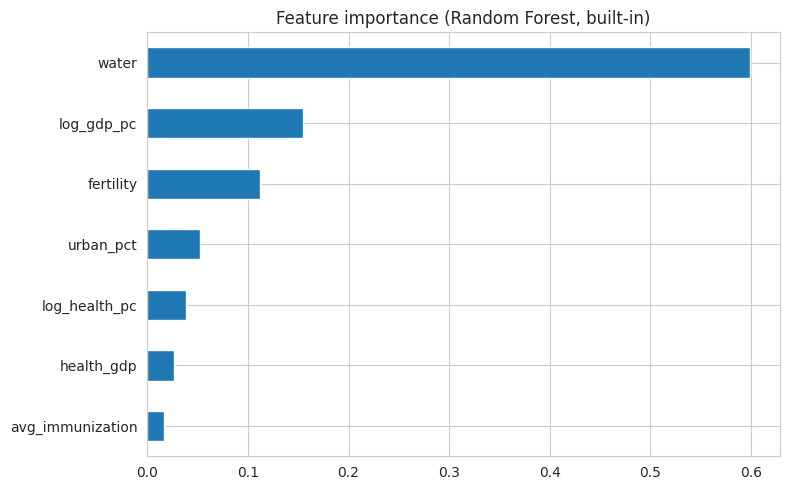

                  built-in  permutation
water                0.599        0.520
log_gdp_pc           0.155        0.159
fertility            0.112        0.140
log_health_pc        0.039        0.069
avg_immunization     0.017        0.013
urban_pct            0.052        0.012
health_gdp           0.026       -0.002


In [42]:
import plotly.express as px
import plotly.graph_objects as go

latest = D[D["year"] == 2023].copy()

def labelled_map(col, title, scale, n=5, always=("Pakistan",)):
    """Choropleth with country names printed on the map for the n highest, n lowest
    and the countries in `always`, so the reader does not have to hover to find them."""
    fig = px.choropleth(latest, locations="code", color=col, hover_name="country",
                        color_continuous_scale=scale, title=title)
    ranked = latest.sort_values(col)
    pick = pd.concat([ranked.head(n), ranked.tail(n), latest[latest["country"].isin(always)]])
    pick = pick.drop_duplicates("code")
    fig.add_trace(go.Scattergeo(locations=pick["code"], locationmode="ISO-3",
                                text=pick["country"], mode="text",
                                textfont=dict(size=10, color="black"),
                                hoverinfo="skip", showlegend=False))
    fig.update_geos(showcountries=True, countrycolor="grey")
    return fig

fig1 = labelled_map("life_exp", "Life expectancy at birth, 2023 (years)", "RdYlGn")
fig1.show()
fig2 = labelled_map("u5_mort", "Under-5 mortality, 2023 (per 1,000 live births)", "RdYlGn_r")
fig2.show()

# Ranked tables, so the names are also readable without the map
for col, label in [("life_exp", "life expectancy (years)"), ("u5_mort", "under-5 mortality (per 1,000)")]:
    r = latest.sort_values(col)[["country", col]].round(1)
    print("Lowest 8 by", label, "\n", r.head(8).to_string(index=False))
    print("Highest 8 by", label, "\n", r.tail(8).to_string(index=False), "\n")

fig1.write_html(FIG + "/map_life_expectancy_2023.html")
fig2.write_html(FIG + "/map_under5_mortality_2023.html")
try:
    fig1.write_image(FIG + "/map_life_expectancy_2023.png", scale=2)
    fig2.write_image(FIG + "/map_under5_mortality_2023.png", scale=2)
except Exception:
    print("PNG export needs the 'kaleido' package; the HTML maps were saved.")

# Part 10. Quality checks and data export

In [ ]:
final_cols = features + ["life_exp", "mort_risk"]
checks = {
    "rows": len(D),
    "countries": D["country"].nunique(),
    "years": str(D["year"].min()) + "-" + str(D["year"].max()),
    "missing values in model columns": int(D[final_cols].isna().sum().sum()),
    "duplicate country-years": int(D.duplicated(["country", "year"]).sum()),
    "infinite values in features": int(np.isinf(D[features]).sum().sum()),
    "life expectancy range": (round(D["life_exp"].min(), 1), round(D["life_exp"].max(), 1)),
    "percent variables outside 0-100": int(((D[["dpt", "measles", "water", "urban_pct"]] < 0) |
                                            (D[["dpt", "measles", "water", "urban_pct"]] > 100)).sum().sum()),
}
for k, v in checks.items():
    print(f"{k:35s}: {v}")
assert checks["missing values in model columns"] == 0 and checks["duplicate country-years"] == 0

In [52]:
D.to_csv(os.path.join(OUT, "wdi_clean_final.csv"), index=False)
D[id_cols + cat_cols + features + targets].to_csv(os.path.join(OUT, "wdi_model_ready.csv"), index=False)
data_dict.to_csv(os.path.join(TABLES, "data_dictionary.csv"), index=False)
summary_stats.to_csv(os.path.join(TABLES, "summary_statistics.csv"))
corr_tests.to_csv(os.path.join(TABLES, "correlation_tests.csv"), index=False)
std_coefs.to_csv(os.path.join(TABLES, "standardized_coefficients.csv"))
reg_single.to_csv(os.path.join(TABLES, "regression_single_split.csv"), index=False)
clf_single.to_csv(os.path.join(TABLES, "classification_single_split.csv"), index=False)
for t, name in [(reg_cv, "regression_10_splits"), (clf_cv, "classification_10_splits")]:
    flat = t.copy()
    flat.columns = ["_".join(c) for c in flat.columns]
    flat.to_csv(os.path.join(TABLES, name + ".csv"))
forecast.to_csv(os.path.join(TABLES, "forecast_2019_2023.csv"), index=False)
imp_table.to_csv(os.path.join(TABLES, "feature_importance.csv"))
dropone.to_csv(os.path.join(TABLES, "drop_one_importance.csv"), index=False)
ext_reg.to_csv(os.path.join(TABLES, "extended_variables_regression.csv"), index=False)

print("Cleaned dataset and result tables saved in outputs/.")
print("Figures saved in outputs/figures/.")

['classification_10_splits.csv', 'classification_single_split.csv', 'correlation_tests.csv', 'data_dictionary.csv', 'drop_one_importance.csv', 'extended_variables_regression.csv', 'feature_importance.csv', 'figures', 'forecast_2019_2023.csv', 'regression_10_splits.csv', 'regression_single_split.csv', 'regression_with_transformer.csv', 'standardized_coefficients.csv', 'summary_statistics.csv', 'transformer_importance.csv', 'wdi_clean_final.csv', 'wdi_model_ready.csv']
Figures: 16
Zip contains: 16 files in figures/ + wdi_clean_final.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 11. Summary and conclusions## 11.1 Research questions## 11.2 Recommendations## 11.3 Limitations